# NB35 — GeoMAE-ST + Persistence-Gated Wind Fusion

## August development experiment • matched seeds, data split, and supervised budget

This notebook tests whether **persistence-gated wind fusion** adds value beyond GeoMAE-ST and the earlier raw-wind integration. It compares three pretrained GeoMAE variants on the same May–July training / August development split:

1. **GeoMAE-ST** — spatial-temporal context, with wind channels and explicit wind context hidden downstream.
2. **GeoMAE-ST-RawWind** — wind channels and explicit wind context available without gating.
3. **GeoMAE-ST-Persistence-Gated-Wind** — wind channels are attenuated unless a neighboring source cell is active on at least 2 of the previous 3 observed days; a learned gate further modulates the explicit wind embedding.

The persistence gate uses only information available on or before forecast origin *t*. It represents predictive association, not evidence of physical fire spread. The directional calculation assumes `wind_u_mean` and `wind_v_mean` point toward where air moves; confirm this against the upstream dataset construction before making a physical interpretation.

**Primary metric:** Emerging-3 PR-AUC. Secondary metrics include overall and persistent PR-AUC, paired seed deltas, date-block bootstrap intervals, and a diagnostic of how often the persistence gate activates.

**Important:** August has already been used for development in earlier experiments. This is exploratory model development, not an untouched confirmation. All variants and seeds are reported; no outcome is guaranteed. NodeGRU-L14 is intentionally not part of this *within-GeoMAE wind-fusion ablation*; its earlier result remains part of the complete thesis benchmark record.

In [2]:
# 1. Imports and reproducibility

from pathlib import Path
import copy
import math
import warnings
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 260)

SEEDS = [11, 22, 33]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("DEVICE:", DEVICE)
print("SEEDS :", SEEDS)

DEVICE: cpu
SEEDS : [11, 22, 33]


In [3]:
# 2. Resolve project files

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for root in candidate_roots:
    data_path = (
        root
        / "data"
        / "processed"
        / "regional_025"
        / "karhut_ml_dataset_regional_025.csv"
    )

    checkpoint_path = (
        root
        / "model_results"
        / "geomae_spatiotemporal"
        / "t2"
        / "models"
        / "geomae_inspired_encoder.pt"
    )

    nb21_pred_path = (
        root
        / "model_results"
        / "regional_025_final_test"
        / "t2"
        / "exports"
        / "final_september_predictions.csv"
    )

    if (
        data_path.exists()
        and checkpoint_path.exists()
        
    ):
        PROJECT_ROOT = root
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the regional dataset and NB24 GeoMAE checkpoint. Set PROJECT_ROOT manually if needed."
    )

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "regional_025"
    / "karhut_ml_dataset_regional_025.csv"
)

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_spatiotemporal"
    / "t2"
    / "models"
    / "geomae_inspired_encoder.pt"
)

NB21_PRED_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "regional_025_final_test"
    / "t2"
    / "exports"
    / "final_september_predictions.csv"
)

RESULT_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "geomae_persistence_gated_wind"
    / "t2"
)

EXPORT_DIR = RESULT_DIR / "exports"
FIGURE_DIR = RESULT_DIR / "figures"
MODEL_DIR = RESULT_DIR / "models"

for p in [
    EXPORT_DIR,
    FIGURE_DIR,
    MODEL_DIR,
]:
    p.mkdir(
        parents=True,
        exist_ok=True,
    )

print("PROJECT_ROOT:", PROJECT_ROOT)
print("RESULT_DIR  :", RESULT_DIR)

PROJECT_ROOT: c:\Users\Asus\Documents\skripsi-karhut
RESULT_DIR  : c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_persistence_gated_wind\t2


In [4]:
# 3. Locked supervised configuration

# Development split
DEV_TRAIN_END = pd.Timestamp("2026-07-31")
DEV_VAL_START = pd.Timestamp("2026-08-01")
DEV_VAL_END = pd.Timestamp("2026-08-31")

# Training
BATCH_SIZE = 256
HEAD_WARMUP_EPOCHS = 2
MAX_FINETUNE_EPOCHS = 14
ONLINE_UPDATE_EPOCHS = 1

ENCODER_LR = 1e-4
HEAD_LR = 5e-4
WEIGHT_DECAY = 1e-4
DROPOUT = 0.20

# Task emphasis locked before seeing NB31 result.
# Emerging-3 is the primary task-specific subgroup.
LOSS_GENERAL_WEIGHT = 0.25
LOSS_EMERGING_WEIGHT = 0.50
LOSS_PERSISTENT_WEIGHT = 0.25

# Wind context
WIND_CONTEXT_DAYS = 3
WIND_DISTANCE_SCALE_KM = 50.0
MIN_WIND_SPEED = 0.5

print("Primary selection metric: August Emerging-3 PR-AUC")
print("Secondary metric       : August overall PR-AUC")
print("Max fine-tune epochs   :", MAX_FINETUNE_EPOCHS)

Primary selection metric: August Emerging-3 PR-AUC
Secondary metric       : August overall PR-AUC
Max fine-tune epochs   : 14


In [5]:
# 4. Load checkpoint and dataset

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
    )

TOKEN_FEATURES = list(
    checkpoint["token_features"]
)

FEATURE_MEAN = {
    k: float(v)
    for k, v
    in checkpoint["feature_mean"].items()
}

FEATURE_STD = {
    k: float(v)
    for k, v
    in checkpoint["feature_std"].items()
}

TEMPORAL_DAYS = int(
    checkpoint["temporal_days"]
)

SPATIAL_OFFSETS = [
    tuple(x)
    for x in checkpoint["spatial_offsets"]
]

CENTER_TOKEN_INDEX = int(
    checkpoint["center_token_index"]
)

PRETRAIN_END = pd.Timestamp(
    checkpoint["pretrain_end"]
)

GRID_STEP = 0.25
N_SPATIAL = len(SPATIAL_OFFSETS)
N_TOKENS = TEMPORAL_DAYS * N_SPATIAL

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["date"],
)

df = (
    df
    .sort_values(["date", "cell_id"])
    .reset_index(drop=True)
)

df["fire_count_log1p"] = np.log1p(
    pd.to_numeric(
        df["fire_count"],
        errors="coerce",
    ).clip(lower=0)
)

df["frp_sum_log1p"] = np.log1p(
    pd.to_numeric(
        df["frp_sum"],
        errors="coerce",
    ).clip(lower=0)
)

required = {
    "date",
    "cell_id",
    "grid_lat",
    "grid_lon",
    "target_fire_active_t1",
    "active_days_prev3_incl_t",
    "fire_active",
    "fire_count",
    "frp_sum",
    "wind_u_mean",
    "wind_v_mean",
    *TOKEN_FEATURES,
}

missing = sorted(
    required - set(df.columns)
)

if missing:
    raise ValueError(
        "Missing required columns:\n"
        + "\n".join(f"- {c}" for c in missing)
    )

print("Token features:", TOKEN_FEATURES)
print("Pretrain end  :", PRETRAIN_END.date())
print("Rows          :", len(df))
print("Cells         :", df["cell_id"].nunique())

Token features: ['temperature_mean', 'temperature_max', 'relative_humidity_mean', 'precipitation_sum', 'boundary_layer_height_mean', 'vapour_pressure_deficit_mean', 'wind_speed_mean', 'wind_speed_max', 'wind_u_mean', 'wind_v_mean', 'fire_active', 'fire_count_log1p', 'frp_sum_log1p']
Pretrain end  : 2026-07-31
Rows          : 16625
Cells         : 133


## Explicit wind-aware spatial context

For every target center cell and each of the last three observed days:

1. inspect the eight neighboring 0.25° cells;
2. take the source-cell wind vector;
3. compare it with the geographic direction **source → target**;
4. keep only the positive alignment component;
5. weight neighbor hotspot activity by:
   - positive wind alignment;
   - distance decay.

This creates physically interpretable predictive context such as:

- aligned neighboring fire-active exposure;
- aligned detection-count exposure;
- aligned FRP exposure;
- nearby activity independent of wind.

It is still interpreted as **predictive spatial-wind association**, not proof of physical flame spread.

In [6]:
# 5. Geometry helpers

EARTH_RADIUS_KM = 6371.0088

def haversine_km(
    lat1,
    lon1,
    lat2,
    lon2,
):
    lat1 = np.radians(
        np.asarray(lat1, dtype=float)
    )
    lon1 = np.radians(
        np.asarray(lon1, dtype=float)
    )
    lat2 = np.radians(
        np.asarray(lat2, dtype=float)
    )
    lon2 = np.radians(
        np.asarray(lon2, dtype=float)
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2.0) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2.0) ** 2
    )

    return (
        2.0
        * EARTH_RADIUS_KM
        * np.arcsin(
            np.sqrt(
                np.clip(
                    a,
                    0.0,
                    1.0,
                )
            )
        )
    )


def source_to_target_unit(
    source_lat,
    source_lon,
    target_lat,
    target_lon,
):
    mean_lat_rad = np.radians(
        (
            float(source_lat)
            + float(target_lat)
        )
        / 2.0
    )

    east_km = (
        (
            float(target_lon)
            - float(source_lon)
        )
        * 111.320
        * np.cos(mean_lat_rad)
    )

    north_km = (
        (
            float(target_lat)
            - float(source_lat)
        )
        * 110.574
    )

    norm = float(
        np.hypot(
            east_km,
            north_km,
        )
    )

    if norm == 0:
        return np.nan, np.nan

    return (
        east_km / norm,
        north_km / norm,
    )


def positive_wind_alignment(
    u,
    v,
    east_unit,
    north_unit,
):
    speed = float(
        np.hypot(
            u,
            v,
        )
    )

    if (
        not np.isfinite(speed)
        or speed < MIN_WIND_SPEED
        or not np.isfinite(east_unit)
        or not np.isfinite(north_unit)
    ):
        return 0.0

    cosine = (
        float(u) * float(east_unit)
        + float(v) * float(north_unit)
    ) / speed

    return float(
        max(
            cosine,
            0.0,
        )
    )

In [7]:
# 6. Recreate NB24 normalization and row lookup

z_cols = []

for col in TOKEN_FEATURES:
    z_col = f"z__{col}"

    mean = FEATURE_MEAN[col]
    std = FEATURE_STD[col]

    if (
        not np.isfinite(std)
        or std == 0
    ):
        std = 1.0

    df[z_col] = (
        pd.to_numeric(
            df[col],
            errors="coerce",
        )
        - mean
    ) / std

    z_cols.append(z_col)

z_matrix = (
    df[z_cols]
    .to_numpy(dtype=np.float32)
)

valid_vector = np.isfinite(
    z_matrix
).all(axis=1)

work = df.copy()

work["lat_key"] = (
    work["grid_lat"]
    .round(3)
)

work["lon_key"] = (
    work["grid_lon"]
    .round(3)
)

row_lookup = {
    (
        pd.Timestamp(row.date),
        round(float(row.lat_key), 3),
        round(float(row.lon_key), 3),
    ): idx
    for idx, row
    in work[
        [
            "date",
            "lat_key",
            "lon_key",
        ]
    ].iterrows()
}

raw_fire_active = (
    pd.to_numeric(
        work["fire_active"],
        errors="coerce",
    )
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

raw_fire_count_log = np.log1p(
    pd.to_numeric(
        work["fire_count"],
        errors="coerce",
    )
    .fillna(0)
    .clip(lower=0)
    .to_numpy(dtype=np.float32)
)

raw_frp_log = np.log1p(
    pd.to_numeric(
        work["frp_sum"],
        errors="coerce",
    )
    .fillna(0)
    .clip(lower=0)
    .to_numpy(dtype=np.float32)
)

raw_wind_u = (
    pd.to_numeric(
        work["wind_u_mean"],
        errors="coerce",
    )
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

raw_wind_v = (
    pd.to_numeric(
        work["wind_v_mean"],
        errors="coerce",
    )
    .fillna(0)
    .to_numpy(dtype=np.float32)
)

print("Normalized token matrix:", z_matrix.shape)

Normalized token matrix: (16625, 13)


In [8]:
# 7. Patch + explicit wind context and persistent-source gate

WIND_FEATURE_NAMES = []
for lag in range(WIND_CONTEXT_DAYS):
    WIND_FEATURE_NAMES.extend([
        f"aligned_active_lag{lag}",
        f"aligned_count_lag{lag}",
        f"aligned_frp_lag{lag}",
        f"near_active_lag{lag}",
    ])

PERSISTENCE_FEATURE_NAMES = [
    "persistent_source_count",
    "persistent_source_strength",
    "persistent_downwind_active",
    "persistent_downwind_frp",
    "persistent_downwind_strength",
    "persistence_gate",
]
WIND_FEATURE_NAMES.extend(PERSISTENCE_FEATURE_NAMES)
N_WIND_FEATURES = len(WIND_FEATURE_NAMES)

def build_sample(center_date, center_lat, center_lon):
    x = np.zeros((N_TOKENS, len(TOKEN_FEATURES)), dtype=np.float32)
    valid = np.zeros(N_TOKENS, dtype=bool)
    token_idx = 0

    # Build the 7-day x 3x3 token patch, oldest day first.
    for day_back in range(TEMPORAL_DAYS - 1, -1, -1):
        token_date = pd.Timestamp(center_date) - pd.Timedelta(days=day_back)
        for dx, dy in SPATIAL_OFFSETS:
            lat = round(float(center_lat + dy * GRID_STEP), 3)
            lon = round(float(center_lon + dx * GRID_STEP), 3)
            idx = row_lookup.get((token_date, lat, lon))
            if idx is not None and valid_vector[idx]:
                x[token_idx] = z_matrix[idx]
                valid[token_idx] = True
            token_idx += 1

    wind_features = []

    # Existing daily source-to-target exposure over t, t-1, t-2.
    for lag in range(WIND_CONTEXT_DAYS):
        source_date = pd.Timestamp(center_date) - pd.Timedelta(days=lag)
        aligned_active = 0.0
        aligned_count = 0.0
        aligned_frp = 0.0
        near_active = 0.0

        for dx, dy in SPATIAL_OFFSETS:
            if dx == 0 and dy == 0:
                continue
            source_lat = round(float(center_lat + dy * GRID_STEP), 3)
            source_lon = round(float(center_lon + dx * GRID_STEP), 3)
            idx = row_lookup.get((source_date, source_lat, source_lon))
            if idx is None:
                continue

            distance = float(haversine_km(source_lat, source_lon, center_lat, center_lon))
            distance_weight = float(np.exp(-distance / WIND_DISTANCE_SCALE_KM))
            east_unit, north_unit = source_to_target_unit(
                source_lat, source_lon, center_lat, center_lon
            )
            alignment = positive_wind_alignment(
                raw_wind_u[idx], raw_wind_v[idx], east_unit, north_unit
            )
            wind_weight = alignment * distance_weight
            active = float(raw_fire_active[idx])
            aligned_active += active * wind_weight
            aligned_count += float(raw_fire_count_log[idx]) * wind_weight
            aligned_frp += float(raw_frp_log[idx]) * wind_weight
            near_active += active * distance_weight

        wind_features.extend([aligned_active, aligned_count, aligned_frp, near_active])

    # Persistence gate: the SAME neighbor must be active on >=2 of t, t-1, t-2.
    persistent_source_count = 0.0
    persistent_source_strength = 0.0
    persistent_downwind_active = 0.0
    persistent_downwind_frp = 0.0
    persistent_downwind_strength = 0.0

    for dx, dy in SPATIAL_OFFSETS:
        if dx == 0 and dy == 0:
            continue
        source_lat = round(float(center_lat + dy * GRID_STEP), 3)
        source_lon = round(float(center_lon + dx * GRID_STEP), 3)
        source_indices = []
        for lag in range(3):
            source_date = pd.Timestamp(center_date) - pd.Timedelta(days=lag)
            source_indices.append(row_lookup.get((source_date, source_lat, source_lon)))

        observed = [idx for idx in source_indices if idx is not None]
        if not observed:
            continue
        active_days = sum(float(raw_fire_active[idx]) >= 1.0 for idx in observed)
        if active_days < 2:
            continue

        persistent_source_count += 1.0
        persistence_ratio = float(active_days / 3.0)
        distance = float(haversine_km(source_lat, source_lon, center_lat, center_lon))
        distance_weight = float(np.exp(-distance / WIND_DISTANCE_SCALE_KM))
        persistent_source_strength += persistence_ratio * distance_weight

        # Most recent available wind at source cell; no t+1 data are used.
        source_idx = source_indices[0] if source_indices[0] is not None else observed[0]
        east_unit, north_unit = source_to_target_unit(
            source_lat, source_lon, center_lat, center_lon
        )
        alignment = positive_wind_alignment(
            raw_wind_u[source_idx], raw_wind_v[source_idx], east_unit, north_unit
        )
        downwind_weight = persistence_ratio * distance_weight * alignment
        persistent_downwind_strength += downwind_weight
        persistent_downwind_active += float(raw_fire_active[source_idx]) * downwind_weight
        persistent_downwind_frp += float(raw_frp_log[source_idx]) * downwind_weight

    # Bounded gate = local persistent-source presence x mean positive downwind alignment.
    presence_gate = min(persistent_source_strength, 1.0)
    direction_gate = persistent_downwind_strength / max(persistent_source_strength, 1e-8)
    persistence_gate = float(np.clip(presence_gate * direction_gate, 0.0, 1.0))

    wind_features.extend([
        persistent_source_count,
        persistent_source_strength,
        persistent_downwind_active,
        persistent_downwind_frp,
        persistent_downwind_strength,
        persistence_gate,
    ])

    return x, valid, np.asarray(wind_features, dtype=np.float32)

print("Explicit wind feature count:", N_WIND_FEATURES)
print("Persistence rule: same neighbor active >=2 of 3 observed days")

Explicit wind feature count: 18
Persistence rule: same neighbor active >=2 of 3 observed days


In [9]:
# 8. Build all supervised samples

min_sample_date = (
    work["date"].min()
    + pd.Timedelta(
        days=TEMPORAL_DAYS - 1
    )
)

meta_source = (
    work[
        (
            work["date"]
            >= min_sample_date
        )
        &
        (
            work[
                "target_fire_active_t1"
            ].notna()
        )
    ][
        [
            "date",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "target_fire_active_t1",
            "active_days_prev3_incl_t",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

patches = []
valid_masks = []
wind_context = []
meta_rows = []

for row in meta_source.itertuples(
    index=False
):
    x, valid, wind = build_sample(
        row.date,
        row.grid_lat,
        row.grid_lon,
    )

    if not valid[
        CENTER_TOKEN_INDEX
    ]:
        continue

    patches.append(x)
    valid_masks.append(valid)
    wind_context.append(wind)

    meta_rows.append(
        {
            "date": pd.Timestamp(
                row.date
            ),
            "cell_id": row.cell_id,
            "grid_lat": float(
                row.grid_lat
            ),
            "grid_lon": float(
                row.grid_lon
            ),
            "target_fire_active_t1": int(
                row.target_fire_active_t1
            ),
            "active_days_prev3_incl_t": float(
                row.active_days_prev3_incl_t
            ),
        }
    )

X = np.stack(
    patches
).astype(np.float32)

VALID = np.stack(
    valid_masks
).astype(bool)

WIND = np.stack(
    wind_context
).astype(np.float32)

META = pd.DataFrame(
    meta_rows
)

print("X     :", X.shape)
print("VALID :", VALID.shape)
print("WIND  :", WIND.shape)
print("META  :", META.shape)

X     : (15827, 63, 13)
VALID : (15827, 63)
WIND  : (15827, 18)
META  : (15827, 6)


In [10]:
# 9. Standardize explicit wind features using May-July only.
# Keep persistence_gate in its interpretable raw [0, 1] range.

dev_train_mask = (META["date"] <= DEV_TRAIN_END).to_numpy()
WIND_GATE_INDEX = WIND_FEATURE_NAMES.index("persistence_gate")
assert WIND_GATE_INDEX == len(WIND_FEATURE_NAMES) - 1

WIND_CORE = WIND[:, :-1]
WIND_GATE_RAW = np.clip(
    np.nan_to_num(WIND[:, -1], nan=0.0, posinf=0.0, neginf=0.0), 0.0, 1.0
)
WIND_CORE_NAMES = WIND_FEATURE_NAMES[:-1]

wind_mean = np.nanmean(WIND_CORE[dev_train_mask], axis=0)
wind_std = np.nanstd(WIND_CORE[dev_train_mask], axis=0)
wind_std = np.where(np.isfinite(wind_std) & (wind_std > 1e-8), wind_std, 1.0)

WIND_Z_CORE = (WIND_CORE - wind_mean) / wind_std
WIND_Z_CORE = np.nan_to_num(
    WIND_Z_CORE, nan=0.0, posinf=0.0, neginf=0.0
).astype(np.float32)
WIND_Z = np.concatenate([WIND_Z_CORE, WIND_GATE_RAW[:, None].astype(np.float32)], axis=1)

display(pd.DataFrame({
    "feature": WIND_CORE_NAMES,
    "train_mean": wind_mean,
    "train_std": wind_std,
}))
print("Raw persistence gate summary:")
display(pd.Series(WIND_GATE_RAW).describe())

,feature,train_mean,train_std
0,aligned_active_lag0,0.087855,0.219441
1,aligned_count_lag0,0.103036,0.293723
2,aligned_frp_lag0,0.181125,0.513566
3,near_active_lag0,0.279869,0.506120
4,aligned_active_lag1,0.084070,0.214283
5,aligned_count_lag1,0.097810,0.283018
6,aligned_frp_lag1,0.171190,0.492616
7,near_active_lag1,0.268024,0.491854
8,aligned_active_lag2,0.081887,0.211442
9,aligned_count_lag2,0.094868,0.278162


Raw persistence gate summary:


count    15827.000000
mean         0.117146
std          0.189495
min          0.000000
25%          0.000000
50%          0.000000
75%          0.234738
max          0.958339
dtype: float64

In [11]:
# 10. Restore exact NB24 encoder

class SpatiotemporalMaskedEncoder(nn.Module):
    def __init__(
        self,
        n_features,
        d_model=64,
        nhead=4,
        num_layers=2,
        dim_feedforward=128,
        dropout=0.10,
    ):
        super().__init__()

        self.n_features = n_features
        self.d_model = d_model

        self.input_proj = nn.Linear(
            n_features,
            d_model,
        )

        self.mask_token = nn.Parameter(
            torch.zeros(
                1,
                1,
                d_model,
            )
        )

        self.time_embedding = nn.Embedding(
            TEMPORAL_DAYS,
            d_model,
        )

        self.space_embedding = nn.Embedding(
            N_SPATIAL,
            d_model,
        )

        encoder_layer = (
            nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=nhead,
                dim_feedforward=dim_feedforward,
                dropout=0.10,
                batch_first=True,
                norm_first=True,
                activation="gelu",
            )
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
        )

        self.norm = nn.LayerNorm(
            d_model
        )

        self.reconstruction_head = nn.Linear(
            d_model,
            n_features,
        )

        token_time = []
        token_space = []

        for t in range(
            TEMPORAL_DAYS
        ):
            for s in range(
                N_SPATIAL
            ):
                token_time.append(t)
                token_space.append(s)

        self.register_buffer(
            "token_time",
            torch.tensor(
                token_time,
                dtype=torch.long,
            ),
            persistent=False,
        )

        self.register_buffer(
            "token_space",
            torch.tensor(
                token_space,
                dtype=torch.long,
            ),
            persistent=False,
        )

    def encode(
        self,
        x,
        valid_mask,
        mask_positions=None,
    ):
        h = self.input_proj(x)

        if mask_positions is not None:
            mask_token = (
                self.mask_token.expand(
                    x.shape[0],
                    x.shape[1],
                    -1,
                )
            )

            h = torch.where(
                mask_positions.unsqueeze(-1),
                mask_token,
                h,
            )

        positional = (
            self.time_embedding(
                self.token_time
            )
            + self.space_embedding(
                self.token_space
            )
        )

        h = (
            h
            + positional.unsqueeze(0)
        )

        h = self.encoder(
            h,
            src_key_padding_mask=(
                ~valid_mask
            ),
        )

        return self.norm(h)

    def forward(
        self,
        x,
        valid_mask,
        mask_positions=None,
    ):
        h = self.encode(
            x,
            valid_mask,
            mask_positions,
        )

        recon = (
            self.reconstruction_head(
                h
            )
        )

        return recon, h


state = checkpoint[
    "model_state_dict"
]

D_MODEL = int(
    state[
        "input_proj.weight"
    ].shape[0]
)

DIM_FEEDFORWARD = int(
    state[
        "encoder.layers.0.linear1.weight"
    ].shape[0]
)

layer_numbers = []

for key in state:
    if key.startswith(
        "encoder.layers."
    ):
        parts = key.split(".")

        if len(parts) > 2:
            try:
                layer_numbers.append(
                    int(parts[2])
                )
            except ValueError:
                pass

NUM_LAYERS = (
    max(layer_numbers) + 1
    if layer_numbers
    else 2
)

NHEAD = 4

def make_pretrained_encoder():
    encoder = (
        SpatiotemporalMaskedEncoder(
            n_features=len(
                TOKEN_FEATURES
            ),
            d_model=D_MODEL,
            nhead=NHEAD,
            num_layers=NUM_LAYERS,
            dim_feedforward=(
                DIM_FEEDFORWARD
            ),
        )
    )

    encoder.load_state_dict(
        state
    )

    return encoder

test_encoder = (
    make_pretrained_encoder()
)

print("D_MODEL         :", D_MODEL)
print("NUM_LAYERS      :", NUM_LAYERS)
print("DIM_FEEDFORWARD :", DIM_FEEDFORWARD)
print("Pretrained encoder restored.")

D_MODEL         : 64
NUM_LAYERS      : 2
DIM_FEEDFORWARD : 128
Pretrained encoder restored.


### Matched-input intervention

The original NB31 `GeoMAESTWindClassifier` remains unchanged. We use the same pretrained checkpoint for all pretrained variants, the same 7 × 3×3 tensor shape, and the same head architecture. Only the *observed input* changes:

- **Temporal-only:** hide all neighbor tokens for every day (only 7 center-cell tokens remain). Keep the same 63-position positional schema.
- **Without wind:** zero the four standardized wind token channels (`wind_speed_mean`, `wind_speed_max`, `wind_u_mean`, `wind_v_mean`) **and** zero the 12 explicit wind-context channels. The spatial neighboring fire/weather input remains available.
- **ST-Wind:** use every valid token and all wind channels.
- **Scratch ST-Wind:** identical inputs/head, but randomly initialized Transformer rather than the May–July pretrained checkpoint.

Zero on standardized channels means the training-mean value. These input ablations keep parameter count constant. They also create an input distribution shift relative to pretraining; results should be interpreted as feature-availability ablations, not clean causal estimates.

## Regime-aware downstream head

The model knows whether a cell is **Emerging-eligible** at origin day `t` because this depends only on observations already available through `t`.

We therefore use:

- one auxiliary general next-day head;
- one Emerging-eligible head;
- one Persistent-context head.

This is not target leakage:
`active_days_prev3_incl_t` is known before predicting `t+1`.

The final risk score uses:
- Emerging head if recent local activity is zero;
- Persistent head otherwise.

In [12]:
# 11. GeoMAE-ST-Wind classifier

class GeoMAESTWindClassifier(nn.Module):
    def __init__(
        self,
        pretrained_encoder,
        wind_dim,
        d_model,
        dropout=0.20,
    ):
        super().__init__()

        self.encoder = (
            pretrained_encoder
        )

        self.wind_proj = nn.Sequential(
            nn.LayerNorm(
                wind_dim
            ),
            nn.Linear(
                wind_dim,
                32,
            ),
            nn.GELU(),
        )

        fusion_dim = (
            d_model
            + d_model
            + 32
        )

        self.fusion = nn.Sequential(
            nn.LayerNorm(
                fusion_dim
            ),
            nn.Linear(
                fusion_dim,
                128,
            ),
            nn.GELU(),
            nn.Dropout(
                dropout
            ),
            nn.Linear(
                128,
                64,
            ),
            nn.GELU(),
            nn.Dropout(
                dropout
            ),
        )

        self.general_head = nn.Linear(
            64,
            1,
        )

        self.emerging_head = nn.Linear(
            64,
            1,
        )

        self.persistent_head = nn.Linear(
            64,
            1,
        )

    def forward(
        self,
        x,
        valid_mask,
        wind_features,
        emerging_eligible,
    ):
        no_mask = torch.zeros_like(
            valid_mask,
            dtype=torch.bool,
        )

        h = self.encoder.encode(
            x,
            valid_mask,
            no_mask,
        )

        center_h = h[
            :,
            CENTER_TOKEN_INDEX,
            :
        ]

        valid_float = (
            valid_mask
            .unsqueeze(-1)
            .float()
        )

        global_h = (
            (
                h
                * valid_float
            ).sum(dim=1)
            / valid_float.sum(
                dim=1
            ).clamp_min(1.0)
        )

        wind_h = self.wind_proj(
            wind_features
        )

        fused = torch.cat(
            [
                center_h,
                global_h,
                wind_h,
            ],
            dim=1,
        )

        z = self.fusion(
            fused
        )

        general_logit = (
            self.general_head(z)
            .squeeze(-1)
        )

        emerging_logit = (
            self.emerging_head(z)
            .squeeze(-1)
        )

        persistent_logit = (
            self.persistent_head(z)
            .squeeze(-1)
        )

        final_logit = torch.where(
            emerging_eligible.bool(),
            emerging_logit,
            persistent_logit,
        )

        return {
            "general": general_logit,
            "emerging": emerging_logit,
            "persistent": persistent_logit,
            "final": final_logit,
        }

In [13]:
# 12. Dataset helper

class SupervisedPatchDataset(
    Dataset
):
    def __init__(
        self,
        indices,
    ):
        self.indices = np.asarray(
            indices,
            dtype=int,
        )

    def __len__(
        self,
    ):
        return len(
            self.indices
        )

    def __getitem__(
        self,
        i,
    ):
        idx = int(
            self.indices[i]
        )

        emerging = (
            META.iloc[idx][
                "active_days_prev3_incl_t"
            ]
            == 0
        )

        y = int(
            META.iloc[idx][
                "target_fire_active_t1"
            ]
        )

        return (
            torch.from_numpy(
                X[idx]
            ),
            torch.from_numpy(
                VALID[idx]
            ),
            torch.from_numpy(
                WIND_Z[idx]
            ),
            torch.tensor(
                emerging,
                dtype=torch.bool,
            ),
            torch.tensor(
                y,
                dtype=torch.float32,
            ),
            idx,
        )

In [14]:
# 13. Loss helpers

def capped_pos_weight(
    y,
    cap=20.0,
):
    y = np.asarray(
        y,
        dtype=int,
    )

    positives = int(
        y.sum()
    )

    negatives = int(
        len(y)
        - positives
    )

    if positives == 0:
        return 1.0

    return float(
        min(
            negatives
            / positives,
            cap,
        )
    )


def make_loss_config(
    indices,
):
    meta = META.iloc[
        indices
    ]

    y = (
        meta[
            "target_fire_active_t1"
        ]
        .astype(int)
        .to_numpy()
    )

    emerging = (
        meta[
            "active_days_prev3_incl_t"
        ]
        .eq(0)
        .to_numpy()
    )

    persistent = ~emerging

    cfg = {
        "general": capped_pos_weight(
            y
        ),
        "emerging": capped_pos_weight(
            y[
                emerging
            ]
        ),
        "persistent": capped_pos_weight(
            y[
                persistent
            ]
        ),
    }

    return cfg


def compute_loss(
    outputs,
    y,
    emerging,
    loss_cfg,
):
    device = y.device

    bce_general = (
        nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                loss_cfg[
                    "general"
                ],
                device=device,
            )
        )
    )

    general_loss = bce_general(
        outputs[
            "general"
        ],
        y,
    )

    if emerging.any():
        bce_emerging = (
            nn.BCEWithLogitsLoss(
                pos_weight=torch.tensor(
                    loss_cfg[
                        "emerging"
                    ],
                    device=device,
                )
            )
        )

        emerging_loss = (
            bce_emerging(
                outputs[
                    "emerging"
                ][
                    emerging
                ],
                y[
                    emerging
                ],
            )
        )
    else:
        emerging_loss = (
            general_loss
            * 0.0
        )

    persistent = (
        ~emerging
    )

    if persistent.any():
        bce_persistent = (
            nn.BCEWithLogitsLoss(
                pos_weight=torch.tensor(
                    loss_cfg[
                        "persistent"
                    ],
                    device=device,
                )
            )
        )

        persistent_loss = (
            bce_persistent(
                outputs[
                    "persistent"
                ][
                    persistent
                ],
                y[
                    persistent
                ],
            )
        )
    else:
        persistent_loss = (
            general_loss
            * 0.0
        )

    total = (
        LOSS_GENERAL_WEIGHT
        * general_loss
        + LOSS_EMERGING_WEIGHT
        * emerging_loss
        + LOSS_PERSISTENT_WEIGHT
        * persistent_loss
    )

    return total

In [15]:
# 14. Prediction and metric helpers

@torch.no_grad()
def predict_indices(
    model,
    indices,
):
    dataset = (
        SupervisedPatchDataset(
            indices
        )
    )

    loader = DataLoader(
        dataset,
        batch_size=512,
        shuffle=False,
        num_workers=0,
    )

    rows = []

    model.eval()

    for (
        x_batch,
        valid_batch,
        wind_batch,
        emerging_batch,
        y_batch,
        idx_batch,
    ) in loader:
        x_batch = (
            x_batch
            .to(DEVICE)
        )

        valid_batch = (
            valid_batch
            .to(DEVICE)
        )

        wind_batch = (
            wind_batch
            .to(DEVICE)
        )

        emerging_batch = (
            emerging_batch
            .to(DEVICE)
        )

        outputs = model(
            x_batch,
            valid_batch,
            wind_batch,
            emerging_batch,
        )

        score = torch.sigmoid(
            outputs["final"]
        ).cpu().numpy()

        for j, idx in enumerate(
            idx_batch.numpy()
        ):
            rows.append(
                {
                    "sample_idx": int(
                        idx
                    ),
                    "score": float(
                        score[j]
                    ),
                }
            )

    pred = pd.DataFrame(
        rows
    )

    meta = (
        META.iloc[
            pred[
                "sample_idx"
            ].to_numpy()
        ]
        .reset_index(drop=True)
        .copy()
    )

    meta[
        "score"
    ] = pred[
        "score"
    ].to_numpy()

    return meta


def pr_auc_safe(
    y,
    score,
):
    y = np.asarray(
        y,
        dtype=int,
    )

    if y.sum() == 0:
        return np.nan

    return float(
        average_precision_score(
            y,
            score,
        )
    )


def evaluate_prediction_df(
    pred_df,
):
    overall_pr = pr_auc_safe(
        pred_df[
            "target_fire_active_t1"
        ],
        pred_df[
            "score"
        ],
    )

    emerging_mask = (
        pred_df[
            "active_days_prev3_incl_t"
        ].eq(0)
    )

    persistent_mask = (
        ~emerging_mask
    )

    emerging_pr = pr_auc_safe(
        pred_df.loc[
            emerging_mask,
            "target_fire_active_t1",
        ],
        pred_df.loc[
            emerging_mask,
            "score",
        ],
    )

    persistent_pr = pr_auc_safe(
        pred_df.loc[
            persistent_mask,
            "target_fire_active_t1",
        ],
        pred_df.loc[
            persistent_mask,
            "score",
        ],
    )

    return {
        "overall_pr_auc": overall_pr,
        "emerging_pr_auc": emerging_pr,
        "persistent_pr_auc": persistent_pr,
    }

In [16]:
# 15. One training epoch

def set_seed(
    seed,
):
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            seed
        )


def make_model(
    seed,
):
    set_seed(seed)

    encoder = (
        make_pretrained_encoder()
    )

    model = (
        GeoMAESTWindClassifier(
            pretrained_encoder=encoder,
            wind_dim=N_WIND_FEATURES,
            d_model=D_MODEL,
            dropout=DROPOUT,
        )
        .to(DEVICE)
    )

    return model


def make_optimizer(
    model,
):
    encoder_params = list(
        model.encoder.parameters()
    )

    head_params = [
        p
        for name, p
        in model.named_parameters()
        if not name.startswith(
            "encoder."
        )
    ]

    optimizer = torch.optim.AdamW(
        [
            {
                "params": encoder_params,
                "lr": ENCODER_LR,
            },
            {
                "params": head_params,
                "lr": HEAD_LR,
            },
        ],
        weight_decay=WEIGHT_DECAY,
    )

    return optimizer


def train_epoch(
    model,
    indices,
    optimizer,
    loss_cfg,
    freeze_encoder=False,
):
    if freeze_encoder:
        for p in model.encoder.parameters():
            p.requires_grad = False
    else:
        for p in model.encoder.parameters():
            p.requires_grad = True

    dataset = (
        SupervisedPatchDataset(
            indices
        )
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
    )

    model.train()

    losses = []

    for (
        x_batch,
        valid_batch,
        wind_batch,
        emerging_batch,
        y_batch,
        _,
    ) in loader:
        x_batch = (
            x_batch
            .to(DEVICE)
        )

        valid_batch = (
            valid_batch
            .to(DEVICE)
        )

        wind_batch = (
            wind_batch
            .to(DEVICE)
        )

        emerging_batch = (
            emerging_batch
            .to(DEVICE)
        )

        y_batch = (
            y_batch
            .to(DEVICE)
        )

        optimizer.zero_grad()

        outputs = model(
            x_batch,
            valid_batch,
            wind_batch,
            emerging_batch,
        )

        loss = compute_loss(
            outputs,
            y_batch,
            emerging_batch,
            loss_cfg,
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0,
        )

        optimizer.step()

        losses.append(
            float(
                loss.detach()
                .cpu()
            )
        )

    return float(
        np.mean(losses)
    )

In [17]:
# 16. Development indices

train_idx = np.flatnonzero(
    META[
        "date"
    ].le(
        DEV_TRAIN_END
    ).to_numpy()
)

val_idx = np.flatnonzero(
    META[
        "date"
    ].between(
        DEV_VAL_START,
        DEV_VAL_END,
    ).to_numpy()
)

print("Train rows:", len(train_idx))
print("Val rows  :", len(val_idx))

print(
    "Train positives:",
    int(
        META.iloc[
            train_idx
        ][
            "target_fire_active_t1"
        ].sum()
    ),
)

print(
    "Val positives  :",
    int(
        META.iloc[
            val_idx
        ][
            "target_fire_active_t1"
        ].sum()
    ),
)

Train rows: 10507
Val rows  : 4123
Train positives: 816
Val positives  : 2169


# Part A — Freeze the ablation protocol

Run every variant on the **same May–July train / August development rows**. The default *full* experiment uses three fixed seeds and **nine** supervised fine-tuning epochs (the NB31 August-frozen count), preceded by two head-only warm-up epochs. The same nine-epoch budget is applied to every variant, but note it was initially selected in NB31 for the proposed variant. This is a limitation in matching model-selection effort.

For a quick debugging run, set `QUICK_MODE=True` before running the training cell. **Never report quick-mode metrics as final ablation evidence.**

In [18]:
# 17. Explicit wind-fusion experiment lock — do not alter after seeing scores.
QUICK_MODE = False

ABLATION_SEEDS = [11, 22, 33] if not QUICK_MODE else [11]
ABLATION_EPOCHS = 9 if not QUICK_MODE else 2
ABLATION_WARMUP = 2 if not QUICK_MODE else 1

VARIANT_ORDER = [
    "GeoMAE-ST",
    "GeoMAE-ST-RawWind",
    "GeoMAE-ST-Persistence-Gated-Wind",
]

LOCK = pd.DataFrame([
    {
        "Variant": v,
        "Pretrained": True,
        "Spatial context": True,
        "Wind integration": (
            "Hidden" if v == "GeoMAE-ST"
            else "Raw" if v == "GeoMAE-ST-RawWind"
            else "Persistence gate + learned gate"
        ),
        "Supervised epochs": ABLATION_EPOCHS,
        "Warmup epochs": ABLATION_WARMUP,
        "Seeds": str(ABLATION_SEEDS),
    }
    for v in VARIANT_ORDER
])
display(LOCK)
print("QUICK_MODE:", QUICK_MODE)
print("Train: through 2026-07-31 | Development: 2026-08-01 through 2026-08-31")
print("August has already been used for development; this run is exploratory.")

,Variant,Pretrained,Spatial context,Wind integration,Supervised epochs,Warmup epochs,Seeds
0,GeoMAE-ST,True,True,Hidden,9,2,"[11, 22, 33]"
1,GeoMAE-ST-RawWind,True,True,Raw,9,2,"[11, 22, 33]"
2,GeoMAE-ST-Persistence-Gated-Wind,True,True,Persistence gate + learned gate,9,2,"[11, 22, 33]"


QUICK_MODE: False
Train: through 2026-07-31 | Development: 2026-08-01 through 2026-08-31
August has already been used for development; this run is exploratory.


In [19]:
# 18. Matched GeoMAE-ST variants: no wind, raw wind, persistence-gated wind.

WIND_TOKEN_INDICES = [
    i for i, col in enumerate(TOKEN_FEATURES)
    if col in {"wind_speed_mean", "wind_speed_max", "wind_u_mean", "wind_v_mean"}
]
assert len(WIND_TOKEN_INDICES) == 4, (
    "Expected four wind token channels; verify NB24 features.", TOKEN_FEATURES
)
assert N_SPATIAL == 9 and TEMPORAL_DAYS == 7, (N_SPATIAL, TEMPORAL_DAYS)

class AblationClassifier(GeoMAESTWindClassifier):
    def __init__(self, pretrained_encoder, wind_dim, d_model, variant, dropout=0.20):
        super().__init__(pretrained_encoder, wind_dim, d_model, dropout=dropout)
        if variant not in VARIANT_ORDER:
            raise ValueError(f"Unknown variant: {variant}")
        self.variant = variant
        self.wind_on = variant != "GeoMAE-ST"
        self.learned_wind_gate = nn.Sequential(
            nn.LayerNorm(2 * d_model + 1),
            nn.Linear(2 * d_model + 1, 32),
            nn.GELU(),
            nn.Linear(32, 1),
            nn.Sigmoid(),
        )

    def forward(self, x, valid_mask, wind_features, emerging_eligible):
        x = x.clone()
        wind_features = wind_features.clone()

        if not self.wind_on:
            x[:, :, WIND_TOKEN_INDICES] = 0.0
            wind_features = torch.zeros_like(wind_features)

        # Last wind feature is the unstandardized raw persistence/downwind gate.
        raw_gate = wind_features[:, -1].clamp(0.0, 1.0)
        gated_variant = self.variant == "GeoMAE-ST-Persistence-Gated-Wind"

        # In the gated model, attenuate wind channels inside the 7x3x3 tokens.
        if gated_variant:
            x[:, :, WIND_TOKEN_INDICES] = x[:, :, WIND_TOKEN_INDICES] * raw_gate[:, None, None]

        no_mask = torch.zeros_like(valid_mask, dtype=torch.bool)
        h = self.encoder.encode(x, valid_mask, no_mask)
        center_h = h[:, CENTER_TOKEN_INDEX, :]
        valid_float = valid_mask.unsqueeze(-1).float()
        global_h = (h * valid_float).sum(dim=1) / valid_float.sum(dim=1).clamp_min(1.0)

        wind_h = self.wind_proj(wind_features)
        if gated_variant:
            gate_context = torch.cat([center_h, global_h, raw_gate.unsqueeze(-1)], dim=1)
            learned_gate = self.learned_wind_gate(gate_context).squeeze(-1)
            effective_gate = raw_gate * learned_gate
            wind_h = wind_h * effective_gate.unsqueeze(-1)
            self.last_effective_gate = effective_gate.detach()
        else:
            self.last_effective_gate = raw_gate.detach()

        fused = torch.cat([center_h, global_h, wind_h], dim=1)
        z = self.fusion(fused)
        general_logit = self.general_head(z).squeeze(-1)
        emerging_logit = self.emerging_head(z).squeeze(-1)
        persistent_logit = self.persistent_head(z).squeeze(-1)
        final_logit = torch.where(emerging_eligible.bool(), emerging_logit, persistent_logit)
        return {
            "general": general_logit,
            "emerging": emerging_logit,
            "persistent": persistent_logit,
            "final": final_logit,
        }

def make_ablation_model(seed, variant):
    set_seed(seed)
    encoder = make_pretrained_encoder()
    return AblationClassifier(
        pretrained_encoder=encoder,
        wind_dim=N_WIND_FEATURES,
        d_model=D_MODEL,
        variant=variant,
        dropout=DROPOUT,
    ).to(DEVICE)

assert sum((torch.arange(N_TOKENS) % N_SPATIAL == (CENTER_TOKEN_INDEX % N_SPATIAL)).tolist()) == 7
print("Wind token channels:", [TOKEN_FEATURES[i] for i in WIND_TOKEN_INDICES])
print("Variants:", VARIANT_ORDER)

Wind token channels: ['wind_speed_mean', 'wind_speed_max', 'wind_u_mean', 'wind_v_mean']
Variants: ['GeoMAE-ST', 'GeoMAE-ST-RawWind', 'GeoMAE-ST-Persistence-Gated-Wind']


In [20]:
# 19. Train all variants on identical sample rows with fixed seeds/epochs
# A full run is heavier than NB31. On CPU, expect this to take time.
# Every run uses identical training budget and an independent optimizer.

seed_scores = []
seed_predictions = []
train_y = META.iloc[train_idx]["target_fire_active_t1"].to_numpy()
val_meta = META.iloc[val_idx].reset_index(drop=True)
val_truth = val_meta["target_fire_active_t1"].astype(int).to_numpy()
val_emerging = val_meta["active_days_prev3_incl_t"].eq(0).to_numpy()

for variant in VARIANT_ORDER:
    for seed in ABLATION_SEEDS:
        t0 = time.perf_counter()
        print("\n" + "=" * 68)
        print(f"VARIANT: {variant} | SEED: {seed}")
        print("=" * 68)
        model = make_ablation_model(seed, variant)
        optimizer = make_optimizer(model)
        loss_cfg = make_loss_config(train_idx)
        for ep in range(ABLATION_WARMUP):
            loss = train_epoch(model, train_idx, optimizer, loss_cfg, freeze_encoder=True)
        for ep in range(ABLATION_EPOCHS):
            loss = train_epoch(model, train_idx, optimizer, loss_cfg, freeze_encoder=False)
        pred = predict_indices(model, val_idx)
        assert len(pred) == len(val_idx)
        metrics = evaluate_prediction_df(pred)
        elapsed = time.perf_counter() - t0
        seed_scores.append({
            "Variant": variant,
            "Seed": seed,
            "Emerging PR-AUC": metrics["emerging_pr_auc"],
            "Overall PR-AUC": metrics["overall_pr_auc"],
            "Persistent PR-AUC": metrics["persistent_pr_auc"],
            "Seconds": elapsed,
        })
        pred["Variant"] = variant
        pred["Seed"] = seed
        seed_predictions.append(pred[["date", "cell_id", "Variant", "Seed", "score"]])
        print("Emerging PR-AUC:", round(metrics["emerging_pr_auc"], 6))
        print("Overall PR-AUC :", round(metrics["overall_pr_auc"], 6))
        print("Persistent PR  :", round(metrics["persistent_pr_auc"], 6))
        print("Runtime seconds:", round(elapsed, 1))
        del model, optimizer
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

seed_results = pd.DataFrame(seed_scores)
all_pred = pd.concat(seed_predictions, ignore_index=True)
print("\n=== ALL SEED RESULTS (NO SELECTIVE HIDING) ===")
display(seed_results)


VARIANT: GeoMAE-ST | SEED: 11
Emerging PR-AUC: 0.314427
Overall PR-AUC : 0.762323
Persistent PR  : 0.909557
Runtime seconds: 222.5

VARIANT: GeoMAE-ST | SEED: 22
Emerging PR-AUC: 0.313404
Overall PR-AUC : 0.811529
Persistent PR  : 0.908499
Runtime seconds: 232.9

VARIANT: GeoMAE-ST | SEED: 33
Emerging PR-AUC: 0.321674
Overall PR-AUC : 0.804324
Persistent PR  : 0.906318
Runtime seconds: 232.5

VARIANT: GeoMAE-ST-RawWind | SEED: 11
Emerging PR-AUC: 0.275748
Overall PR-AUC : 0.726696
Persistent PR  : 0.8916
Runtime seconds: 233.0

VARIANT: GeoMAE-ST-RawWind | SEED: 22
Emerging PR-AUC: 0.291093
Overall PR-AUC : 0.738671
Persistent PR  : 0.891584
Runtime seconds: 223.6

VARIANT: GeoMAE-ST-RawWind | SEED: 33
Emerging PR-AUC: 0.281023
Overall PR-AUC : 0.729508
Persistent PR  : 0.892689
Runtime seconds: 221.8

VARIANT: GeoMAE-ST-Persistence-Gated-Wind | SEED: 11
Emerging PR-AUC: 0.324512
Overall PR-AUC : 0.769777
Persistent PR  : 0.911819
Runtime seconds: 218.7

VARIANT: GeoMAE-ST-Persistence

,Variant,Seed,Emerging PR-AUC,Overall PR-AUC,Persistent PR-AUC,Seconds
0,GeoMAE-ST,11,0.314427,0.762323,0.909557,222.494173
1,GeoMAE-ST,22,0.313404,0.811529,0.908499,232.872162
2,GeoMAE-ST,33,0.321674,0.804324,0.906318,232.456087
3,GeoMAE-ST-RawWind,11,0.275748,0.726696,0.891600,232.956142
4,GeoMAE-ST-RawWind,22,0.291093,0.738671,0.891584,223.625807
5,GeoMAE-ST-RawWind,33,0.281023,0.729508,0.892689,221.809477
6,GeoMAE-ST-Persistence-Gated-Wind,11,0.324512,0.769777,0.911819,218.713063
7,GeoMAE-ST-Persistence-Gated-Wind,22,0.321773,0.814484,0.910444,219.935166
8,GeoMAE-ST-Persistence-Gated-Wind,33,0.326971,0.799075,0.907126,221.860138


In [21]:
# 20. Compare ALL seeds and ensemble-mean predictions
assert seed_results.groupby("Variant")["Seed"].nunique().eq(len(ABLATION_SEEDS)).all()
seed_summary = (
    seed_results.groupby("Variant", as_index=False)
    .agg(
        mean_emerging_pr=("Emerging PR-AUC", "mean"),
        std_emerging_pr=("Emerging PR-AUC", "std"),
        mean_overall_pr=("Overall PR-AUC", "mean"),
        mean_persistent_pr=("Persistent PR-AUC", "mean"),
        mean_seconds=("Seconds", "mean"),
    )
)

a = all_pred.groupby(["date", "cell_id", "Variant"], as_index=False).agg(
    score=("score", "mean"),
    score_std=("score", "std"),
)
wide = a.pivot(index=["date", "cell_id"], columns="Variant", values="score").reset_index()
assert len(wide) == len(val_idx), (len(wide), len(val_idx))
val_eval = val_meta[["date", "cell_id", "target_fire_active_t1", "active_days_prev3_incl_t"]].merge(
    wide, on=["date", "cell_id"], how="inner", validate="one_to_one"
)
assert len(val_eval) == len(val_idx)

ensemble_rows=[]
for variant in VARIANT_ORDER:
    s=val_eval[variant]
    em=val_eval["active_days_prev3_incl_t"].eq(0)
    ensemble_rows.append({
        "Variant": variant,
        "Emerging PR-AUC": pr_auc_safe(val_eval.loc[em, "target_fire_active_t1"], s[em]),
        "Overall PR-AUC": pr_auc_safe(val_eval["target_fire_active_t1"], s),
        "Persistent PR-AUC": pr_auc_safe(val_eval.loc[~em, "target_fire_active_t1"], s[~em]),
    })
ensemble_summary = pd.DataFrame(ensemble_rows)
print("SEED MEANS")
display(seed_summary)
print("ENSEMBLE-MEAN PREDICTIONS (AUGUST DEV)")
display(ensemble_summary)

SEED MEANS


,Variant,mean_emerging_pr,std_emerging_pr,mean_overall_pr,mean_persistent_pr,mean_seconds
0,GeoMAE-ST,0.316502,0.004508,0.792726,0.908124,229.274141
1,GeoMAE-ST-Persistence-Gated-Wind,0.324419,0.002600,0.794445,0.909796,220.169456
2,GeoMAE-ST-RawWind,0.282621,0.007796,0.731625,0.891958,226.130475


ENSEMBLE-MEAN PREDICTIONS (AUGUST DEV)


,Variant,Emerging PR-AUC,Overall PR-AUC,Persistent PR-AUC
0,GeoMAE-ST,0.319423,0.797456,0.909002
1,GeoMAE-ST-RawWind,0.285125,0.733742,0.892159
2,GeoMAE-ST-Persistence-Gated-Wind,0.329714,0.798502,0.910610


In [22]:
# 21. Paired deltas on the same dates, samples, and seeds.
paired_tests = [
    ("Raw wind vs no wind", "GeoMAE-ST", "GeoMAE-ST-RawWind"),
    (
        "Persistence-gated fusion vs raw wind",
        "GeoMAE-ST-RawWind",
        "GeoMAE-ST-Persistence-Gated-Wind",
    ),
    (
        "Persistence-gated wind vs no wind",
        "GeoMAE-ST",
        "GeoMAE-ST-Persistence-Gated-Wind",
    ),
]

pair_rows = []
for component, left, right in paired_tests:
    per_seed = []
    for seed in ABLATION_SEEDS:
        aa = seed_results[(seed_results["Variant"] == left) & (seed_results["Seed"] == seed)].iloc[0]
        bb = seed_results[(seed_results["Variant"] == right) & (seed_results["Seed"] == seed)].iloc[0]
        per_seed.append(bb["Emerging PR-AUC"] - aa["Emerging PR-AUC"])
    by_model = ensemble_summary.set_index("Variant")
    pair_rows.append({
        "Component": component,
        "Comparison": f"{right} - {left}",
        "Ensemble Emerging Δ": by_model.loc[right, "Emerging PR-AUC"] - by_model.loc[left, "Emerging PR-AUC"],
        "Ensemble Overall Δ": by_model.loc[right, "Overall PR-AUC"] - by_model.loc[left, "Overall PR-AUC"],
        "Mean paired seed Emerging Δ": float(np.mean(per_seed)),
        "Seeds Δ>0": int(np.sum(np.asarray(per_seed) > 0)),
        "Total seeds": len(per_seed),
    })

paired = pd.DataFrame(pair_rows)
display(paired)

,Component,Comparison,Ensemble Emerging Δ,Ensemble Overall Δ,Mean paired seed Emerging Δ,Seeds Δ>0,Total seeds
0,Raw wind vs no wind,GeoMAE-ST-RawWind - GeoMAE-ST,-0.034297,-0.063714,-0.033880,0,3
1,Persistence-gated fusion vs raw wind,GeoMAE-ST-Persistence-Gated-Wind - GeoMAE-ST-R...,0.044589,0.064760,0.041797,3,3
2,Persistence-gated wind vs no wind,GeoMAE-ST-Persistence-Gated-Wind - GeoMAE-ST,0.010292,0.001046,0.007917,3,3


In [23]:
# 22. Paired date-block bootstrap 95% confidence intervals for Emerging PR-AUC deltas
# Resample August DATES (not independent cells), preserving same blocks for both variants.
# Small number of dates means intervals can be wide; these are exploratory uncertainty estimates.

N_BOOTSTRAPS = 1500 if not QUICK_MODE else 150
rng = np.random.default_rng(20261015)
days = np.array(sorted(val_eval["date"].unique()))
day_indices = [np.flatnonzero(val_eval["date"].eq(day).to_numpy()) for day in days]
emerging_eligible = val_eval["active_days_prev3_incl_t"].eq(0).to_numpy()
y_all = val_eval["target_fire_active_t1"].astype(int).to_numpy()

bootstrap_rows=[]
for component,left,right in paired_tests:
    bootstrap_deltas=[]
    a_pred = val_eval[left].to_numpy()
    b_pred = val_eval[right].to_numpy()
    for _ in range(N_BOOTSTRAPS):
        sampled_days=rng.integers(0,len(days),size=len(days))
        chosen=np.concatenate([day_indices[j] for j in sampled_days])
        chosen=chosen[emerging_eligible[chosen]]
        y=y_all[chosen]
        if y.sum()==0 or y.sum()==len(y):
            continue
        delta=average_precision_score(y,b_pred[chosen])-average_precision_score(y,a_pred[chosen])
        bootstrap_deltas.append(float(delta))
    arr=np.asarray(bootstrap_deltas,dtype=float)
    if not len(arr):
        lower=upper=np.nan
    else:
        lower,upper=np.quantile(arr,[0.025,0.975])
    bootstrap_rows.append({
        "Component":component,
        "Emerging Δ":float(
            average_precision_score(y_all[emerging_eligible],b_pred[emerging_eligible])
            -average_precision_score(y_all[emerging_eligible],a_pred[emerging_eligible])
        ),
        "Date-block 95% CI lower":lower,
        "Date-block 95% CI upper":upper,
        "Bootstrap replicates":len(arr),
        "Clear positive gain?":bool(lower>0) if np.isfinite(lower) else False,
    })
bootstrap_table=pd.DataFrame(bootstrap_rows)
display(bootstrap_table)

,Component,Emerging Δ,Date-block 95% CI lower,Date-block 95% CI upper,Bootstrap replicates,Clear positive gain?
0,Raw wind vs no wind,-0.034297,-0.074924,-0.002554,1500,False
1,Persistence-gated fusion vs raw wind,0.044589,0.014187,0.076388,1500,True
2,Persistence-gated wind vs no wind,0.010292,-0.006324,0.023250,1500,False


In [24]:
# 23. Optional external LR13 baseline on exactly the same August rows.
# This notebook focuses on within-GeoMAE wind fusion. NodeGRU is not part of
# this ablation table; its earlier benchmark result remains in the full record.

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

CURRENT_DAY_FIRE = ["fire_active", "fire_count", "frp_sum"]
FIRE_HISTORY = [
    "fire_count_lag1", "fire_count_lag3", "fire_count_lag7",
    "frp_sum_lag1", "frp_sum_lag3", "frp_sum_lag7",
    "fire_count_roll3", "fire_count_roll7", "frp_sum_roll3", "frp_sum_roll7",
]
FEATURES_13 = CURRENT_DAY_FIRE + FIRE_HISTORY

train_keys = META.iloc[train_idx][["date", "cell_id"]]
val_keys = META.iloc[val_idx][["date", "cell_id"]]
feature_frame = df[["date", "cell_id", *FEATURES_13]]
lr_train = train_keys.merge(feature_frame, on=["date", "cell_id"], validate="one_to_one")
lr_val = val_keys.merge(feature_frame, on=["date", "cell_id"], validate="one_to_one")
train_y_lr = META.iloc[train_idx]["target_fire_active_t1"].astype(int).to_numpy()
assert len(lr_train) == len(train_idx) and len(lr_val) == len(val_idx)
assert np.isfinite(lr_train[FEATURES_13].to_numpy()).all()
assert np.isfinite(lr_val[FEATURES_13].to_numpy()).all()

lr = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(class_weight="balanced", max_iter=1500, random_state=42)),
])
lr.fit(lr_train[FEATURES_13], train_y_lr)
lr_scores = lr.predict_proba(lr_val[FEATURES_13])[:, 1]
lr_predictions = val_keys.copy()
lr_predictions["LR13 baseline (matched train)"] = lr_scores
val_eval = val_eval.merge(lr_predictions, on=["date", "cell_id"], validate="one_to_one")

em = val_eval["active_days_prev3_incl_t"].eq(0)
baseline_summary = pd.DataFrame([{
    "Model": "LR13 baseline (matched train)",
    "Emerging PR-AUC": pr_auc_safe(
        val_eval.loc[em, "target_fire_active_t1"],
        val_eval.loc[em, "LR13 baseline (matched train)"],
    ),
    "Overall PR-AUC": pr_auc_safe(
        val_eval["target_fire_active_t1"],
        val_eval["LR13 baseline (matched train)"],
    ),
    "Persistent PR-AUC": pr_auc_safe(
        val_eval.loc[~em, "target_fire_active_t1"],
        val_eval.loc[~em, "LR13 baseline (matched train)"],
    ),
}])
display(baseline_summary)

,Model,Emerging PR-AUC,Overall PR-AUC,Persistent PR-AUC
0,LR13 baseline (matched train),0.276978,0.877613,0.90917


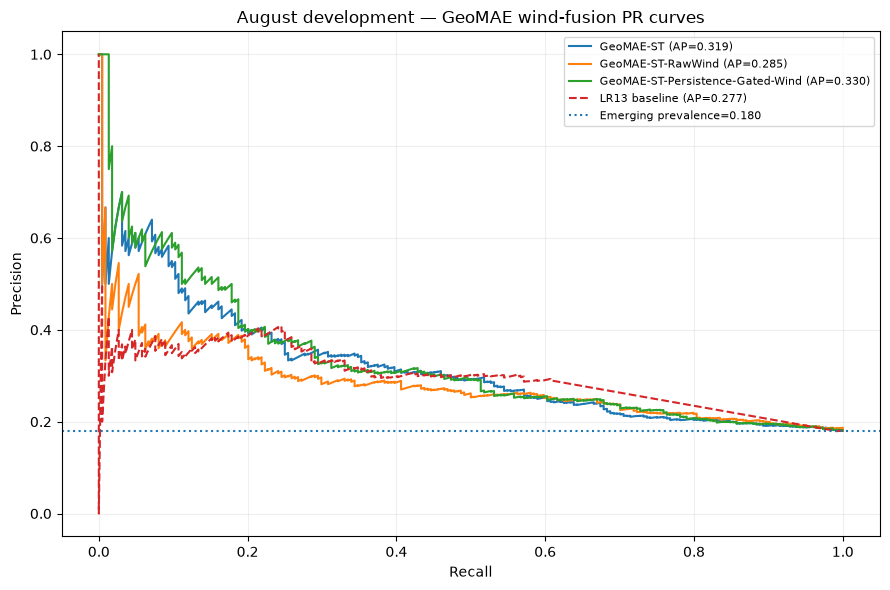

Saved c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_persistence_gated_wind\t2\figures\01_august_emerging_wind_fusion_pr.png


In [25]:
# 24. PR curves on the SAME August Emerging-eligible rows.
em = val_eval["active_days_prev3_incl_t"].eq(0)
y = val_eval.loc[em, "target_fire_active_t1"].astype(int)

fig, ax = plt.subplots(figsize=(9, 6))
for variant in VARIANT_ORDER:
    scores = val_eval.loc[em, variant]
    p, r, _ = precision_recall_curve(y, scores)
    ap = average_precision_score(y, scores)
    ax.plot(r, p, label=f"{variant} (AP={ap:.3f})")

lr_col = "LR13 baseline (matched train)"
p, r, _ = precision_recall_curve(y, val_eval.loc[em, lr_col])
lr_ap = average_precision_score(y, val_eval.loc[em, lr_col])
ax.plot(r, p, linestyle="--", label=f"LR13 baseline (AP={lr_ap:.3f})")
ax.axhline(float(y.mean()), linestyle=":", label=f"Emerging prevalence={y.mean():.3f}")
ax.set(xlabel="Recall", ylabel="Precision", title="August development — GeoMAE wind-fusion PR curves")
ax.legend(fontsize=8, loc="best")
ax.grid(alpha=0.2)
fig.tight_layout()
fig_path = FIGURE_DIR / "01_august_emerging_wind_fusion_pr.png"
fig.savefig(fig_path, dpi=180, bbox_inches="tight")
plt.show()
print("Saved", fig_path)

Raw persistence gate by next-day target, Emerging-eligible August rows:


,target_fire_active_t1,count,mean,median,std
0,0,1017,0.191219,0.137691,0.207404
1,1,224,0.224518,0.190754,0.227156


Single-feature AP of raw persistence gate (diagnostic only): 0.212218
Gate active fraction among Emerging-eligible rows: 0.614


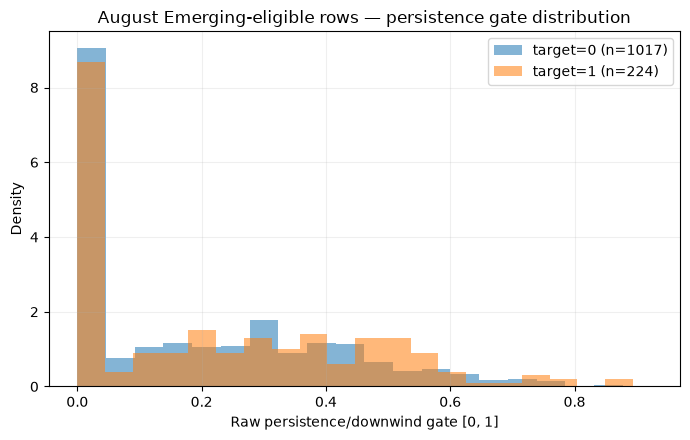

Saved c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_persistence_gated_wind\t2\figures\02_persistence_gate_distribution.png


In [26]:
# 25. Persistence-gate diagnostic: does the gate meaningfully discriminate?
gate_eval = META.iloc[val_idx][
    ["date", "cell_id", "target_fire_active_t1", "active_days_prev3_incl_t"]
].reset_index(drop=True).copy()
gate_eval["persistence_gate"] = WIND[val_idx, -1]
gate_eval["is_emerging"] = gate_eval["active_days_prev3_incl_t"].eq(0)

em_gate = gate_eval[gate_eval["is_emerging"]].copy()
gate_summary = (
    em_gate.groupby("target_fire_active_t1")["persistence_gate"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)
print("Raw persistence gate by next-day target, Emerging-eligible August rows:")
display(gate_summary)

gate_ap = pr_auc_safe(
    em_gate["target_fire_active_t1"].astype(int),
    em_gate["persistence_gate"],
)
print("Single-feature AP of raw persistence gate (diagnostic only):", round(gate_ap, 6))
print("Gate active fraction among Emerging-eligible rows:", round(float((em_gate["persistence_gate"] > 0).mean()), 4))

gate_eval.to_csv(EXPORT_DIR / "persistence_gate_august_diagnostics.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
for label, grp in em_gate.groupby("target_fire_active_t1"):
    ax.hist(
        grp["persistence_gate"].to_numpy(), bins=20, alpha=0.55,
        density=True, label=f"target={int(label)} (n={len(grp)})",
    )
ax.set(
    xlabel="Raw persistence/downwind gate [0, 1]",
    ylabel="Density",
    title="August Emerging-eligible rows — persistence gate distribution",
)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
gate_fig = FIGURE_DIR / "02_persistence_gate_distribution.png"
fig.savefig(gate_fig, dpi=180, bbox_inches="tight")
plt.show()
print("Saved", gate_fig)

In [27]:
# 26. Save all results, including unfavorable results and method lock.
import json

for name, frame in [
    ("seed_results", seed_results),
    ("seed_summary", seed_summary),
    ("ensemble_summary", ensemble_summary),
    ("paired_component_deltas", paired),
    ("date_block_bootstrap_cis", bootstrap_table),
    ("august_baselines", baseline_summary),
    ("all_seed_predictions", all_pred),
    ("all_model_august_predictions", val_eval),
    ("persistence_gate_diagnostics", gate_eval),
    ("persistence_gate_summary", gate_summary),
]:
    frame.to_csv(EXPORT_DIR / f"{name}.csv", index=False)

lock = {
    "task": "Emerging-3 next-day prediction with persistence-gated wind fusion",
    "period": "August development; already used in earlier experiments",
    "training_end": "2026-07-31",
    "validation_start": "2026-08-01",
    "validation_end": "2026-08-31",
    "seeds": ABLATION_SEEDS,
    "finetune_epochs": ABLATION_EPOCHS,
    "head_warmup_epochs": ABLATION_WARMUP,
    "checkpoint": str(CHECKPOINT_PATH),
    "variants": VARIANT_ORDER,
    "quick_mode": QUICK_MODE,
    "persistence_rule": "same neighboring cell active on >=2 of t, t-1, t-2",
    "wind_alignment": "source-to-target direction dotted with U/V assumed to point toward where air moves",
    "restriction": "Exploratory development comparison; no claim of untouched out-of-sample superiority",
}
(EXPORT_DIR / "wind_fusion_method_lock.json").write_text(
    json.dumps(lock, indent=2), encoding="utf-8"
)
print("Exported to", EXPORT_DIR)

Exported to c:\Users\Asus\Documents\skripsi-karhut\model_results\geomae_persistence_gated_wind\t2\exports


# Thesis-safe interpretation and decision rule

- This experiment compares **GeoMAE-ST**, **GeoMAE-ST-RawWind**, and **GeoMAE-ST-Persistence-Gated-Wind** under the same August development rows, seeds, and supervised training budget.
- A positive paired date-block confidence interval supports a wind-fusion improvement only on this development experiment. If it crosses zero or is negative, report that uncertainty honestly.
- The raw gate is constructed from the same neighboring cell's observed activity over *t, t-1, t-2* and source-to-target wind alignment. It does not use the next-day label.
- The learned gate is multiplied by the raw persistence gate. It can down-weight explicit wind context when there is little persistent-source/downwind evidence.
- **Do not tune repeatedly on September**: September has already been used in previous experiments. A fresh period or independent geography is needed for confirmatory evidence.
- The original GeoMAE paper targets 3D point clouds. This is a **GeoMAE-inspired** spatiotemporal adaptation, not the original GeoMAE implementation.
- This notebook intentionally omits NodeGRU from the focused within-GeoMAE ablation; its earlier result remains part of the full benchmark record and must not be erased from the thesis.

### Suggested supervisor narrative

> “Saya membandingkan GeoMAE-ST tanpa wind, GeoMAE-ST dengan wind mentah, dan GeoMAE-ST dengan persistence-gated wind fusion pada split dan budget training yang sama. Gate mensyaratkan sumber tetangga yang sama aktif minimal dua dari tiga hari terakhir dan mengukur alignment arah angin dari sumber menuju target. Saya akan melaporkan semua seed dan ketidakpastian; jika gate tidak meningkatkan PR-AUC, hasil itu menjadi batasan formulasi wind yang diuji, bukan alasan untuk menyembunyikan hasil.”